# Calling our model server

Team 6, floor-plan similarity search · AI Methods I hackathon, IAAC 2026

This notebook calls the **online** model server on Render, like any other program would. It sends one floor plan and prints the five plans with the most similar layout that the server finds out of the 5,000 of CubiCasa5K, and shows the rooms the model sees in it.

| Section | What it does |
|---|---|
| 1 | wakes the server up (the free plan sleeps after 15 minutes) |
| 2 | calls the API with `gradio_client`, the easy way |
| 3 | calls it with plain HTTP in two steps, like the Cloudflare app will |
| 4 | asks `/embed` for the code of the plan, the 128 numbers the search compares |
| 5 | shows the five plans that came back, as drawn and as rooms |

It only needs `gradio_client`, `requests`, `pillow` and `numpy`: `pip install gradio_client requests pillow numpy`.

In [1]:
import base64
import io
import json
import time
from pathlib import Path

import requests
from gradio_client import Client
from IPython.display import display
from PIL import Image

MODEL_URL = "https://hackathon-team6-cubicasa.onrender.com"     # our server on Render
EXAMPLE = Path("examples/plan_high_quality_architectural_1191.png")

image_b64 = base64.b64encode(EXAMPLE.read_bytes()).decode()     # HTTP carries text, so the image travels as base64
print(f"{EXAMPLE.name}: {EXAMPLE.stat().st_size / 1024:.1f} KB as a file, {len(image_b64) / 1024:.1f} KB as base64")

plan_high_quality_architectural_1191.png: 11.1 KB as a file, 14.8 KB as base64


## 1. Wake the server up

On the free plan the server falls asleep after 15 minutes without requests. The first request wakes it, which takes about a minute, so we knock until it answers.

In [2]:
def wake_up(url, tries=10, wait=10):
    for attempt in range(1, tries + 1):
        start = time.time()
        try:
            requests.get(url, timeout=60).raise_for_status()
            print(f"awake: answered in {time.time() - start:.1f} s (attempt {attempt})")
            return True
        except requests.RequestException as error:
            print(f"attempt {attempt}: not yet ({type(error).__name__}), waiting {wait} s")
            time.sleep(wait)
    return False


wake_up(MODEL_URL)

awake: answered in 0.8 s (attempt 1)


True

## 2. The easy way: `gradio_client`

`gradio_client` hides the two HTTP steps: we give it the base64 text and get the dictionary back.

In [3]:
client = Client(MODEL_URL, verbose=False)
start = time.time()
result = client.predict(image_b64, api_name="/predict")
print(f"answered in {time.time() - start:.2f} s")
print(f"place on the atlas: {result['atlas_xy']}")
for match in result["matches"]:
    print(f"{match['rank']}. {match['id']:35s} distance {match['distance']:6.2f}")

answered in 1.22 s
place on the atlas: [0.2469, 0.3552]
1. high_quality_architectural/1191     distance  18.04
2. high_quality_architectural/9620     distance 106.43
3. high_quality_architectural/9109     distance 108.32
4. high_quality_architectural/5070     distance 123.03
5. colorful/2571                       distance 123.25


The example comes from the collection, so the first match is the plan itself, at a much smaller distance than the others. The next four are other homes, at distances around 80 or more: those are the real answers.

## 3. Plain HTTP, in two steps

This is what the Cloudflare app will do on Wednesday, in JavaScript:
1. `POST /gradio_api/call/predict` with the input: the server answers with an `event_id`, a kind of ticket number;
2. `GET /gradio_api/call/predict/<event_id>`: the result comes on the line after `event: complete`.

In [4]:
ticket = requests.post(f"{MODEL_URL}/gradio_api/call/predict", json={"data": [image_b64]}, timeout=120)
event_id = ticket.json()["event_id"]
print("event_id:", event_id)

answer = requests.get(f"{MODEL_URL}/gradio_api/call/predict/{event_id}", timeout=120).text
print(answer[:160], "...")

result_http = json.loads(answer.split("event: complete\ndata: ", 1)[1].splitlines()[0])[0]
print("same matches as gradio_client:", [m["id"] for m in result_http["matches"]] == [m["id"] for m in result["matches"]])

event_id: 78b26c2bf91a453ea4466a864910874f


event: complete
data: [{"matches": [{"rank": 1, "id": "high_quality_architectural/1191", "distance": 18.04, "atlas_xy": [0.2573, 0.3666], "image_png_base64": "i ...
same matches as gradio_client: True


## 4. Only the code: `/embed`

`/embed` gives back the code of a plan, the 128 numbers of the encoder, without searching. An app can store these codes in its own database and compare them there, for example to add the plans its users upload to the catalog. The code is the same one `/predict` compares: the distance printed below has to match the distance of match 1 above.

In [ ]:
import numpy as np

embedding = client.predict(image_b64, api_name="/embed")
print(f"{embedding['size']} numbers, the first five: {embedding['code'][:5]}")

#the stored code of plan 1191 is on Hugging Face, with the codes of the other 4,999 plans
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   #a harmless warning about progress bars
from huggingface_hub import hf_hub_download
codes = np.load(hf_hub_download("iaac-maai/hackathon-team6-cubicasa-ae", "collection_codes_v3.npy"))
ids = json.load(open(hf_hub_download("iaac-maai/hackathon-team6-cubicasa-ae", "collection_ids.json")))
distance = np.linalg.norm(codes[ids.index("high_quality_architectural/1191")] - np.array(embedding["code"]))
print(f"distance to the stored code of plan 1191: {distance:.2f} (match 1 of /predict: {result['matches'][0]['distance']})")

## 5. The plans that came back

Every match carries its plan as drawn and its room map as small PNGs (base64), so a page can show them without asking anyone else. Top row: our plan, then the five matches. Bottom row: the rooms the model sees in our plan, then the rooms of the five matches.

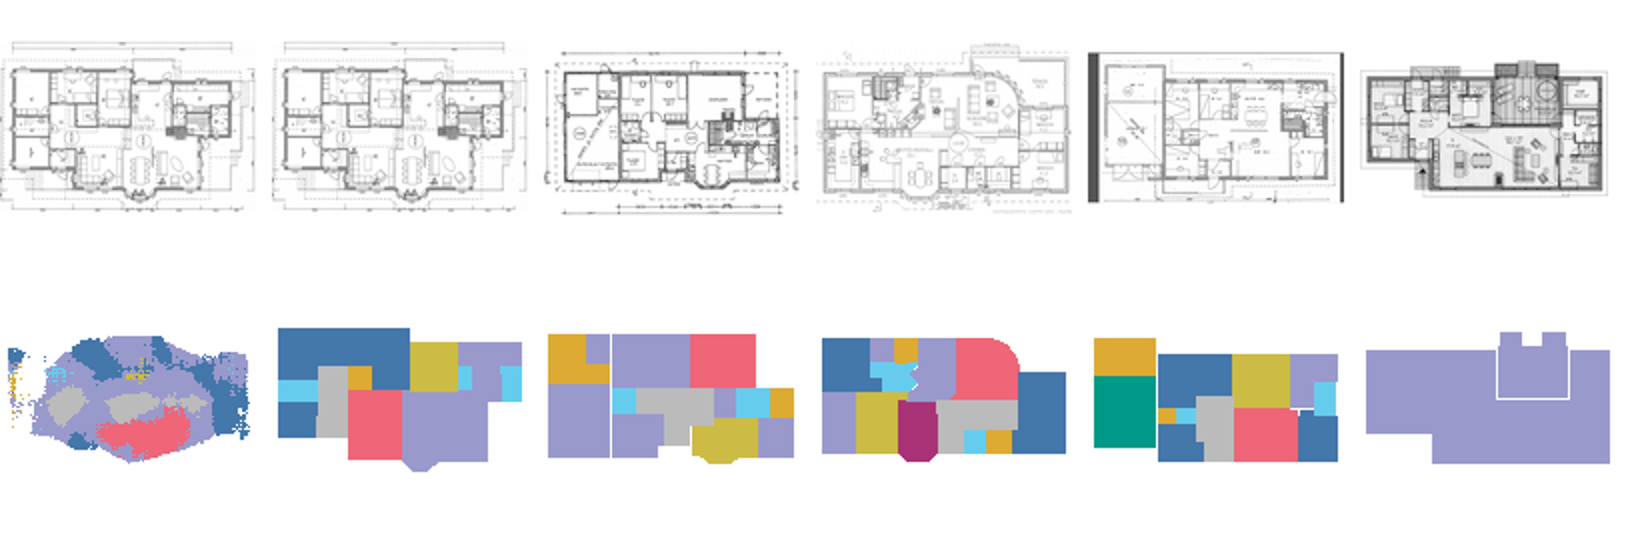

room colours: {'Bedroom': '#4477aa', 'Bath': '#66ccee', 'Sauna': '#228833', 'Kitchen': '#ccbb44', 'LivingRoom': '#ee6677', 'Dining': '#aa3377', 'Circulation': '#bbbbbb', 'Storage': '#ddaa33', 'Garage': '#009988', 'Other': '#9999cc'}
left: our plan · then matches 1 to 5: 18.0, 106.4, 108.3, 123.0, 123.2


In [5]:
def from_base64(text):
    return Image.open(io.BytesIO(base64.b64decode(text))).convert("RGB")


query = Image.open(EXAMPLE).convert("RGB").resize((128, 128))
drawings = [query] + [from_base64(m["image_png_base64"]) for m in result["matches"]]
rooms = [from_base64(result["rooms_png_base64"])] + [from_base64(m["rooms_png_base64"]) for m in result["matches"]]

sheet = Image.new("RGB", (len(drawings) * 136, 2 * 136), "white")
for i, (plan, room_map) in enumerate(zip(drawings, rooms)):
    sheet.paste(plan, (i * 136, 0))
    sheet.paste(room_map, (i * 136, 136))
display(sheet.resize((sheet.width * 2, sheet.height * 2)))
print("room colours:", result["room_colours"])
print("left: our plan · then matches 1 to 5:", ", ".join(f"{m['distance']:.1f}" for m in result["matches"]))

## What we see

- The server answers from another program in two ways, with the same five plans.
- Match 1 is the example itself, at a much smaller distance than the others, which shows that the server prepares and cleans the image like the training notebook: a different preprocessing would give a different code.
- The other matches are chosen by layout: the model behind the server (v3) learned to draw the rooms from the lines, so close codes mean similar rooms in similar places, whatever the drawing style.
- The bottom row shows what the model sees in our plan, next to the real rooms of the matches.
- Every match also has its place on the atlas (`atlas_xy`), and so does our plan: that's what the app will use to show it on the map.